# 1 Dataset Introduction

Financial markets are closely linked: the price of one asset is often affected by movements in stock markets, other commodities, currencies and the wider economy. Gold is a common example. Investors often treat it as a "safe haven" and buy it when stock markets fall or inflation rises, and because it is priced in US dollars it also responds to changes in the dollar's value and in interest rates.

This dataset brings these factors together in one daily record, covering two major US stock indices (the S&P 500 and NASDAQ), five commodities (gold, silver, oil, platinum and palladium), two exchange rates and three US economic indicators. This makes it suitable for studying how the assets relate to one another and for building models that predict a future price, such as gold, from the behaviour of the rest of the market.

## 1.1 Dataset Introduction 

The dataset was retrieved from Kaggle, where it was published by the user franciscogcc under the title "Gold Price Regression". It is a daily time series of financial information for market indices, commodities, economic indicators and foreign exchange rates. The market indices and commodities are represented by the price of the exchange-traded fund (ETF) that tracks each one, rather than by the index or spot price itself. Kaggle does not verify uploaded datasets, so this source should be treated with more caution than a curated repository such as UC Irvine. The dataset can be found at the following URL: 

https://www.kaggle.com/datasets/franciscogcc/financial-data

The dataset contains forty-seven (47) attributes over 3,904 rows, covering trading days from 14 January 2010 to 23 October 2024. The file does not define a target. As the dataset was published for regression on the gold price, gold close is treated as the target, with the remaining forty-six (46) attributes as features. The attributes are defined as the following types:

- <mark>Date</mark>: date Presented as a string in the format YYYY-MM-DD. For example: 2010-01-14.
- <mark>Numerical (Continuous)</mark>: the open, high, low and close prices of sp500, nasdaq, silver, oil, platinum, palladium and gold; the daily range (high-low) of each asset except gold; the exchange rates usd_chf and eur_usd; and the macroeconomic indicators us_rates_%, CPI and GDP (39 attributes in total). Prices and rates can take any real value and have no defined upper limit.
- <mark>Numerical (Discrete)</mark>: sp500 volume, nasdaq volume, silver volume, oil volume, platinum volume, palladium volume, gold volume. Volumes are counts of units traded, so they only take whole-number values, although the file stores them as decimals.

There are no categorical attributes. Around 5% of rows are empty apart from the date; these appear to be non-trading days. us_rates_%, CPI and GDP are published monthly or quarterly, so they are present on only around 5%, 5% and 1% of rows respectively. They would need to be forward-filled or removed before modelling. Table 1 summarises the attributes.


**Red Wine Quality**

Herein, the objective of the supervised learning task is to use regression techniques to accurately predict the quality score of a red wine based on features such as its alcohol content, acidity, sulphates and sulphur dioxide levels. This can also be determined from the following:

1) The target variable of quality provides the ground truth, providing real world data that is known to be true, providing an expected outcome for the created model (MathWorks, 2024).
2) quality is a discrete numerical variable taking whole-number values between 0 and 10 (3 to 8 in this dataset), so it is predicted directly as a numerical value. Alternatively, these values could be separated into "good" (quality ≥ 7) and "not good" (quality < 7) during data processing to allow for binary classification.
3) Regression techniques predict numerical values, making them suitable for estimating a wine's quality score.

# Red Wine Quality Dataset – Attributes

| Attribute | Data Type | Variable Type | Description |
|---|---|---|---|
| fixed acidity | float64 | Continuous numerical (input) | Acids that don't evaporate, mainly tartaric (g tartaric acid/dm³). They give the wine its sharpness and structure. |
| volatile acidity | float64 | Continuous numerical (input) | Acids that evaporate, mainly acetic (g acetic acid/dm³). At high levels the wine tastes of vinegar. |
| citric acid | float64 | Continuous numerical (input) | Citric acid content (g/dm³). It adds freshness and flavour. |
| residual sugar | float64 | Continuous numerical (input) | Sugar left after fermentation stops (g/dm³). |
| chlorides | float64 | Continuous numerical (input) | Salt content (g sodium chloride/dm³). |
| free sulfur dioxide | float64 | Continuous numerical (input) | Unbound SO₂ (mg/dm³). It stops microbes and oxidation. |
| total sulfur dioxide | float64 | Continuous numerical (input) | Free plus bound SO₂ (mg/dm³). High levels can be smelled and tasted. |
| density | float64 | Continuous numerical (input) | Density of the wine (g/cm³). It depends mainly on alcohol and sugar content. |
| pH | float64 | Continuous numerical (input) | Acidity on a 0–14 scale, where lower means more acidic. Most wines are between 3 and 4. |
| sulphates | float64 | Continuous numerical (input) | Potassium sulphate (g/dm³), an additive that raises SO₂ levels and helps preserve the wine. |
| alcohol | float64 | Continuous numerical (input) | Alcohol content (% by volume). |
| quality | int64 | Discrete ordinal (target) | The median score given by wine experts, on a 0–10 scale. Only 3–8 appear in this data. |

## 2 Exploratory Data Analysis

With the identification of the dataset, and the supervised learning task being defined as Red Wine Quality and regression respectively, exploratory data analysis (EDA) can be undertaken to facilitate a deeper understanding of the structure of the data, as well as allowing for identification of issues with data quality (IBM, 2024). This is particularly important for this dataset, as although it contains no missing values, 240 rows are exact duplicates, and the target is heavily imbalanced towards average scores of 5 and 6. Furthermore, by creating visualisations of the dataset, it is easier to identify any patterns, trends, or correlations between the chemical properties of a wine and its quality. With conclusions drawn from this exploration, suitable machine learning algorithms and models can be identified, and features can be engineered to improve the performance of the chosen model(s). These model(s) can then be evaluated for their efficacy when provided data of a similar format to the original dataset.

Within the following section, questions and assumptions about the dataset will be proposed. Then an explanation of how data will be split into training, validation, and testing sets will be provided; the split will be stratified on quality so that the rare very low and very high scores appear in every set. This will be followed by EDA, defining the process and results, which will then be measured against the previously proposed questions and assumptions.

### 2.1 Question(s) identification

Research questions should allow the researcher or investigator to set out what they want to know as a hypothesis, regardless of whether the result support the hypothesis or not (Mayo et al., 2013). By providing well posed questions and assumptions the EDA process will be able to support or reject their claims (Lane, 2018). Table 2 below provides several questions related to the dataset and their associated assumptions.

| ID | Question | Assumption |
|---|---|---|
| RQ1 | Does alcohol content impact wine quality? | It is expected that wines with a higher alcohol content will receive higher quality scores, as alcohol contributes to the body and flavour of a wine. |
| RQ2 | Does volatile acidity impact wine quality? | Volatile acidity is mainly acetic acid, which gives an unpleasant vinegar taste at high levels. It is expected that higher volatile acidity will result in lower quality scores. |
| RQ3 | Do sulphates impact wine quality? | Sulphates contribute to sulphur dioxide levels, which protect wine from spoiling. It is expected that moderate increases in sulphates will be associated with higher quality, as the wine is better preserved. |
| RQ4 | Does citric acid impact wine quality? | Citric acid adds freshness to wine, so it is expected that wines with higher citric acid will receive slightly higher quality scores. |
| RQ5 | Does residual sugar impact wine quality? | As the dataset contains red wines, which are generally dry with little sugar remaining, it is expected that residual sugar will have little impact on quality. |
| RQ6 | Are any of the chemical properties closely related to each other? | It is expected that some features will be strongly correlated, such as free and total sulfur dioxide (as free is part of total), fixed acidity and pH, and density and alcohol. Such pairs may carry duplicate information. |

Table 2: Questions and Assumptions

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_val_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

from sklearn.metrics import accuracy_score, recall_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
DATA_PATH = "../datasets/"
wine_qual = pd.read_csv(DATA_PATH + "winequality-red.csv")
print(wine_qual.shape)
wine_qual.head

(1599, 12)


<bound method NDFrame.head of       fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0               7.4             0.700         0.00             1.9      0.076   
1               7.8             0.880         0.00             2.6      0.098   
2               7.8             0.760         0.04             2.3      0.092   
3              11.2             0.280         0.56             1.9      0.075   
4               7.4             0.700         0.00             1.9      0.076   
...             ...               ...          ...             ...        ...   
1594            6.2             0.600         0.08             2.0      0.090   
1595            5.9             0.550         0.10             2.2      0.062   
1596            6.3             0.510         0.13             2.3      0.076   
1597            5.9             0.645         0.12             2.0      0.075   
1598            6.0             0.310         0.47             3.6      0.067  

#### Check for missing values

In [3]:
wine_qual.isnull().sum()
X = wine_qual.drop(columns="quality")
y = wine_qual["quality"]


In [4]:
# Split off 60% training data & 40% temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=42)

# Split the temporary data in half: 20% validation, 20% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

print(len(X_train), len(X_val), len(X_test))

959 320 320


In [5]:
# Print column names, non-null value count, and data types to system output
wine_qual.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [6]:
unique_values = wine_qual['fixed acidity'].unique()
print(unique_values)

[ 7.4  7.8 11.2  7.9  7.3  7.5  6.7  5.6  8.9  8.5  8.1  7.6  6.9  6.3
  7.1  8.3  5.2  5.7  8.8  6.8  4.6  7.7  8.7  6.4  6.6  8.6 10.2  7.
  7.2  9.3  8.   9.7  6.2  5.   4.7  8.4 10.1  9.4  9.   8.2  6.1  5.8
  9.2 11.5  5.4  9.6 12.8 11.  11.6 12.  15.  10.8 11.1 10.  12.5 11.8
 10.9 10.3 11.4  9.9 10.4 13.3 10.6  9.8 13.4 10.7 11.9 12.4 12.2 13.8
  9.1 13.5 10.5 12.6 14.  13.7  9.5 12.7 12.3 15.6  5.3 11.3 13.   6.5
 12.9 14.3 15.5 11.7 13.2 15.9 12.1  5.1  4.9  5.9  6.   5.5]


In [7]:
wine_qual.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


## Univariate Analysis

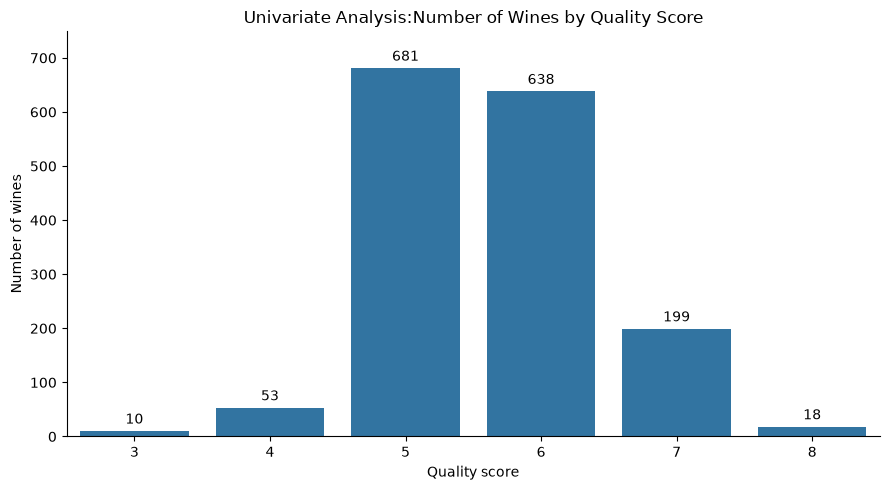

In [8]:
# Number of wines for each quality score
plt.figure(figsize=(9,5))
# Set x axis as quality
quality_plot = sns.countplot(x=wine_qual["quality"])

# Put the count above each bar
quality_plot.bar_label(quality_plot.containers[0], padding=3)

# Title the plot
quality_plot.set_title("Univariate Analysis:Number of Wines by Quality Score")
quality_plot.set_xlabel("Quality score")
quality_plot.set_ylabel("Number of wines")
quality_plot.margins(y=0.1) # leave room above the tallest bar for its label
sns.despine()

plt.tight_layout()
plt.show()

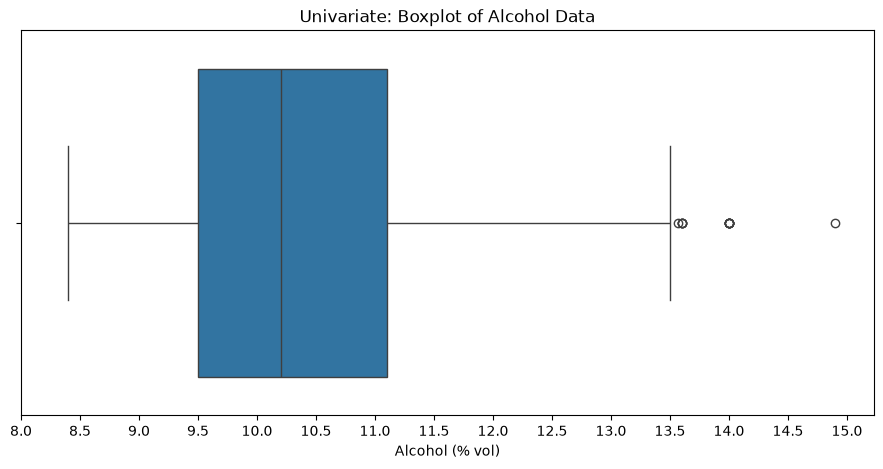

In [9]:
plt.figure(figsize=(11,5))

# Set x axis as temp
sns.boxplot(x = wine_qual["alcohol"])

# Title the plot
plt.title("Univariate: Boxplot of Alcohol Data")
# Label the axis
plt.xlabel("Alcohol (% vol)")

# Get the minimum and maximum values for temp column for use with numpy
min_alc = np.floor(wine_qual["alcohol"]).min()
max_alc = np.ceil(wine_qual["alcohol"]).max()

# Add ticks on x axis for more accurate value reading
plt.xticks(np.arange(min_alc, max_alc + 0.5, 0.5))

# Show the plot
plt.show()

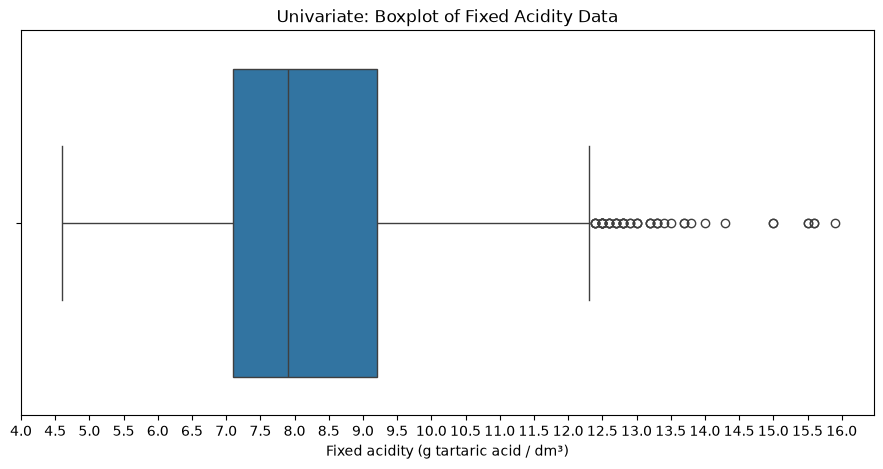

In [10]:
plt.figure(figsize=(11,5))

# Set x axis as temp
sns.boxplot(x = wine_qual["fixed acidity"])

# Title the plot
plt.title("Univariate: Boxplot of Fixed Acidity Data")
# Label the axis
plt.xlabel("Fixed acidity (g tartaric acid / dm³)")

# Get the minimum and maximum values for temp column for use with numpy
min_fa = np.floor(wine_qual["fixed acidity"]).min()
max_fa = np.ceil(wine_qual["fixed acidity"]).max()

# Add ticks on x axis for more accurate value reading
plt.xticks(np.arange(min_fa, max_fa + 0.5, 0.5))

# Show the plot
plt.show()

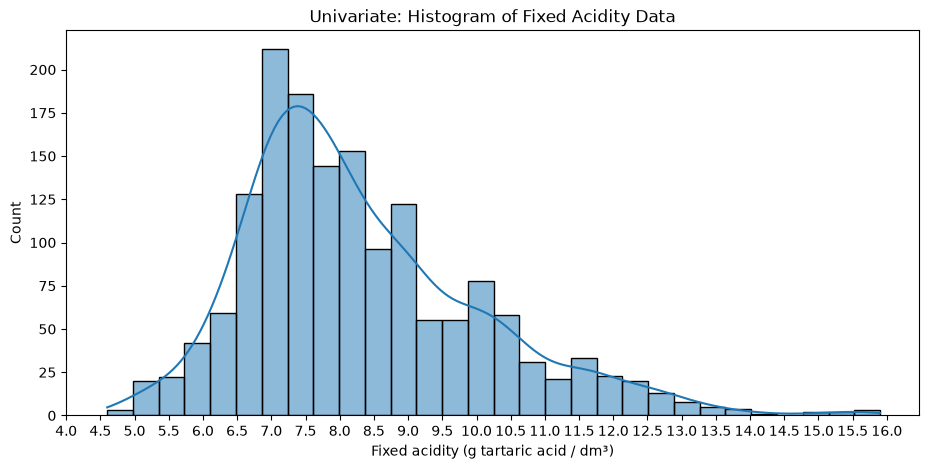

In [11]:
plt.figure(figsize=(11,5))

# Set x axis as temp
sns.histplot(wine_qual["fixed acidity"], kde=True, bins=30)

# Title the plot
plt.title("Univariate: Histogram of Fixed Acidity Data")
# Label the axis
plt.xlabel("Fixed acidity (g tartaric acid / dm³)")

# Get the minimum and maximum values for temp column for use with numpy
min_fa = np.floor(wine_qual["fixed acidity"]).min()
max_fa = np.ceil(wine_qual["fixed acidity"]).max()

# Add ticks on x axis for more accurate value reading
plt.xticks(np.arange(min_fa, max_fa + 0.5, 0.5))

# Show the plot
plt.show()

## Bivariate Analysis

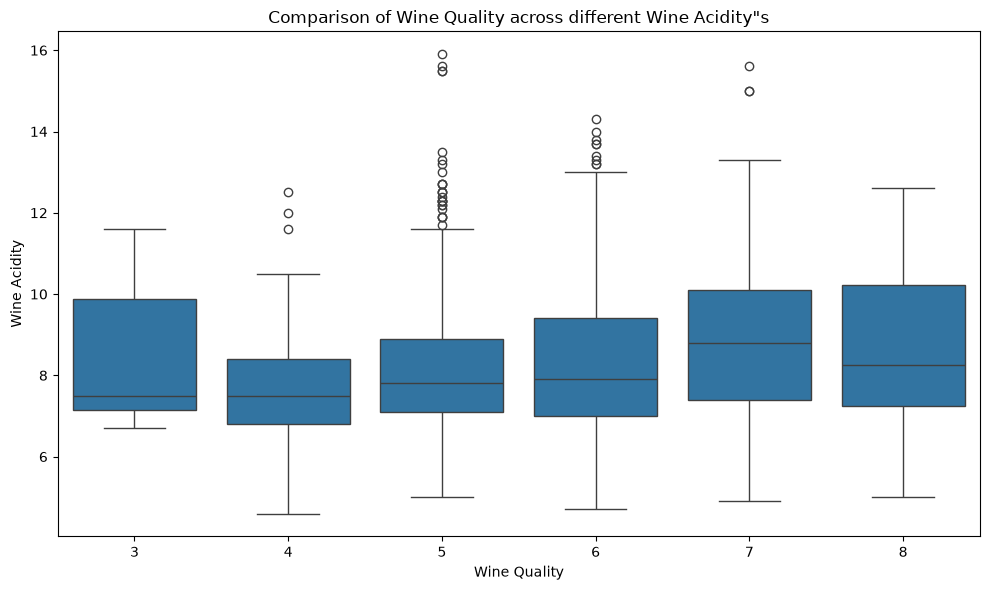

In [12]:
plt.figure(figsize=(10,6))
sns.boxplot(x=wine_qual["quality"], y= wine_qual["fixed acidity"])

# Title the plot
plt.title('Comparison of Wine Quality across different Wine Acidity"s')

# Label the axis
plt.xlabel("Wine Quality")
plt.ylabel("Wine Acidity")

# Show the plot
plt.tight_layout()
plt.show()

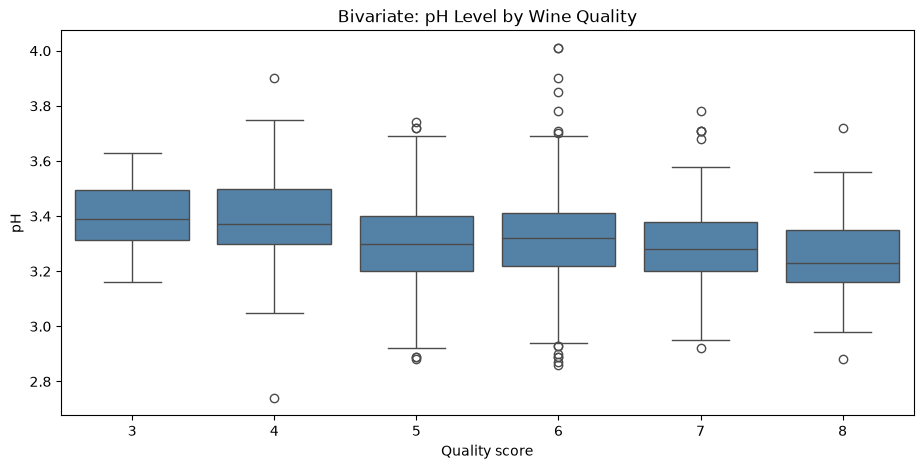

         count  median  mean
quality                     
3           10    3.39  3.40
4           53    3.37  3.38
5          681    3.30  3.30
6          638    3.32  3.32
7          199    3.28  3.29
8           18    3.23  3.27
Correlation: -0.058


In [14]:
# Filter wine quality column to only required rows
required_scores = [4, 5, 6, 7]          # change to the scores you want to keep
wine_filtered = wine_qual[wine_qual["quality"].isin(required_scores)]

# Compare the Wine Quality across different ph levels
plt.figure(figsize=(11, 5))

# One box of pH values for each quality score
sns.boxplot(x=wine_qual["quality"], y=wine_qual["pH"], color="steelblue")

# Title and axis labels
plt.title("Bivariate: pH Level by Wine Quality")
plt.xlabel("Quality score")
plt.ylabel("pH")

plt.show()

# Number of wines and average pH for each quality score
print(wine_qual.groupby("quality")["pH"].agg(["count", "median", "mean"]).round(2))

# Correlation between pH and quality
print("Correlation:", round(wine_qual["pH"].corr(wine_qual["quality"]), 3))


In [15]:
# Group the filtered group description for wine quality
wine_filtered.groupby("quality")["pH"].describe()

,count,mean,std,min,25%,50%,75%,max
quality,,,,,,,,
4,53.0,3.381509,0.181441,2.74,3.30,3.37,3.50,3.90
5,681.0,3.304949,0.150618,2.88,3.20,3.30,3.40,3.74
6,638.0,3.318072,0.153995,2.86,3.22,3.32,3.41,4.01
7,199.0,3.290754,0.150101,2.92,3.20,3.28,3.38,3.78


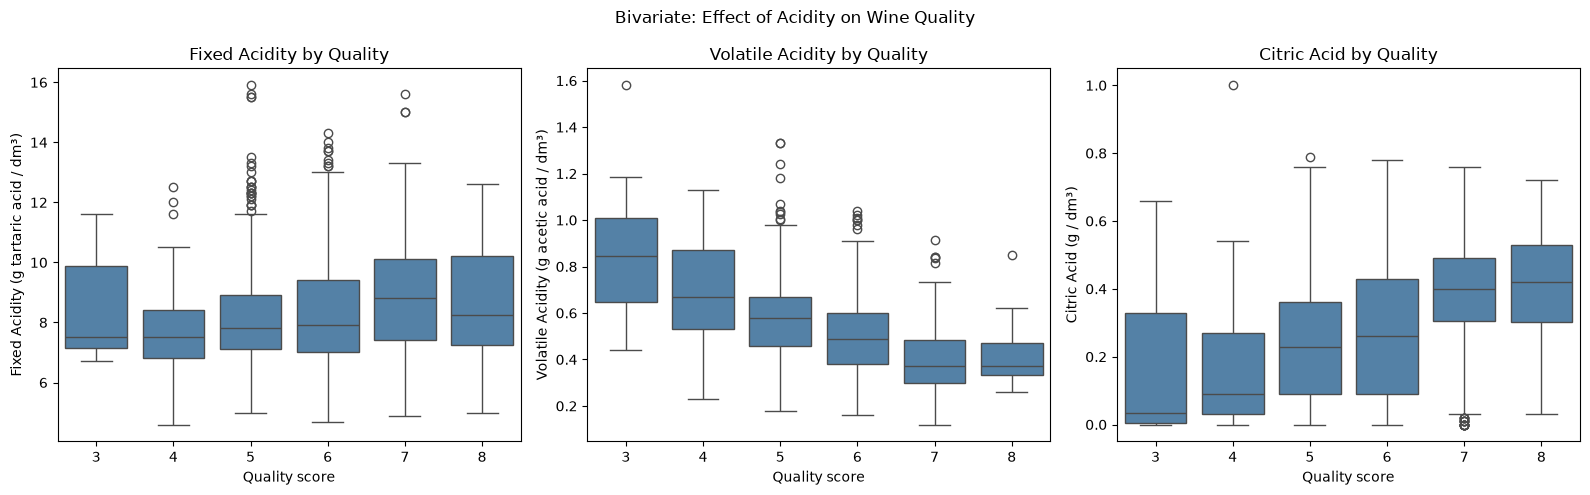

         fixed acidity  volatile acidity  citric acid
quality                                              
3                 7.50              0.84         0.04
4                 7.50              0.67         0.09
5                 7.80              0.58         0.23
6                 7.90              0.49         0.26
7                 8.80              0.37         0.40
8                 8.25              0.37         0.42
fixed acidity       0.124
volatile acidity   -0.391
citric acid         0.226
dtype: float64


In [16]:
# Effect of acidity on the wine quality
acidity_cols = ["fixed acidity", "volatile acidity", "citric acid"]
units = ["g tartaric acid / dm³", "g acetic acid / dm³", "g / dm³"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# One box plot per acidity column, with a box for each quality score
for ax, col, unit in zip(axes, acidity_cols, units):
    sns.boxplot(x=wine_qual["quality"], y=wine_qual[col], color="steelblue", ax=ax)
    ax.set_title(f"{col.title()} by Quality")
    ax.set_xlabel("Quality score")
    ax.set_ylabel(f"{col.title()} ({unit})")

plt.suptitle("Bivariate: Effect of Acidity on Wine Quality")
plt.tight_layout()
plt.show()

# Median of each acidity measure for each quality score
print(wine_qual.groupby("quality")[acidity_cols].median().round(2))

# Correlation of each acidity measure with quality
print(wine_qual[acidity_cols].corrwith(wine_qual["quality"]).round(3))

## Multivariate Analysis

### Numerical Multivariate Analysis

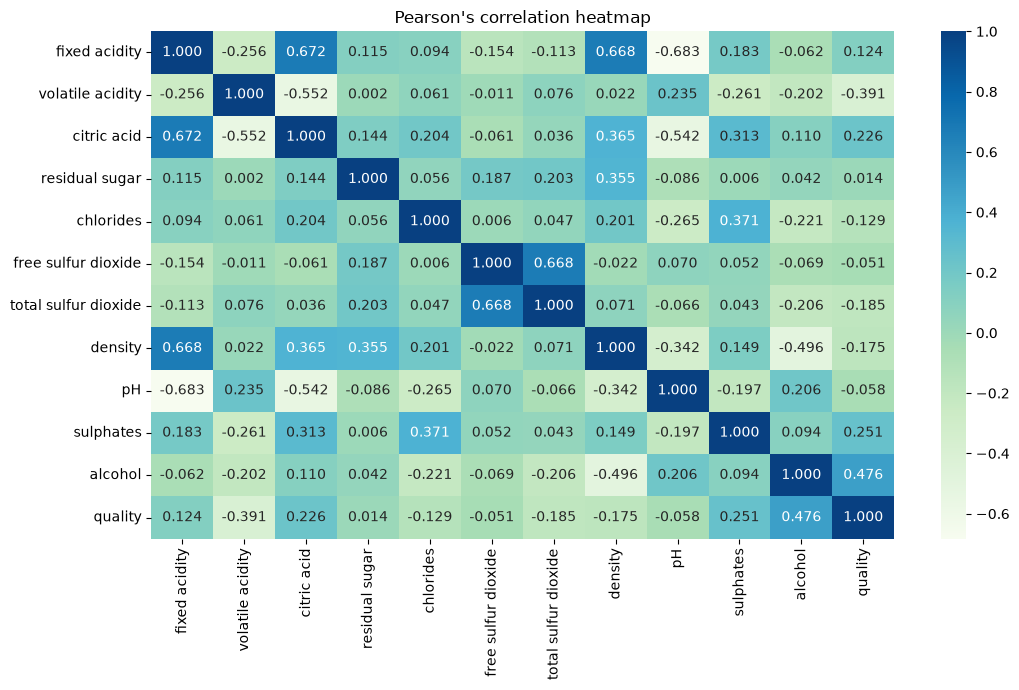

In [21]:
# Numerical Multivariate Analysis
# Correlation matrix numerical start
# Pearson correlation

corr = wine_qual.corr(method="pearson")


mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(11, 7))

sns.heatmap(corr, annot=True, cmap="GnBu", fmt=".3f")

# Title the plot
plt.title("Pearson's correlation heatmap")

# Show the plot
plt.tight_layout()
plt.show()

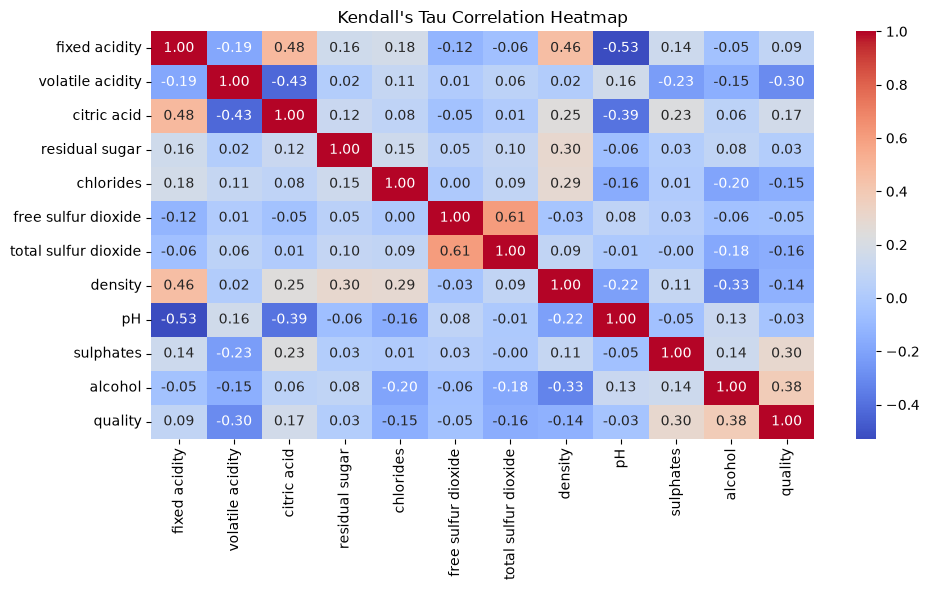

In [22]:
kendall_corr = wine_qual.corr(method="kendall")

plt.figure(figsize=(10,6))

# Build heatmap
sns.heatmap(kendall_corr, annot=True, cmap="coolwarm", fmt=".2f")

# Title of the plat
plt.title("Kendall's Tau Correlation Heatmap")

plt.tight_layout()
plt.show()

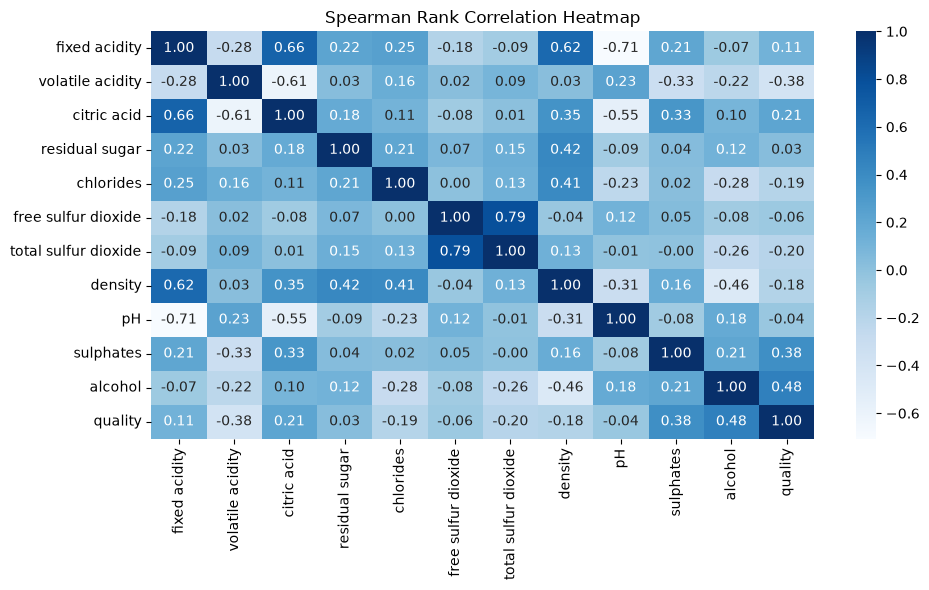

In [23]:
# Spearman Rank Correlation Heatmap

spearman_corr = wine_qual.corr(method="spearman")

plt.figure(figsize=(10, 6))

# Build Heatmap
sns.heatmap(spearman_corr, annot=True, cmap="Blues", fmt=".2f")

# Title the plot
plt.title("Spearman Rank Correlation Heatmap")

plt.tight_layout()
plt.show()

# 3. Experimental Design